In [1]:
# Cell 4a-0
import sys
print(sys.executable)   # should end in ...\load-shedding-capstone\venv\Scripts\python.exe
!{sys.executable} -m pip install xgboost

d:\load-shedding-capstone\venv\Scripts\python.exe



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re
import numpy as np
import pandas as pd

train = pd.read_csv("../data/processed/train_features.csv")
test  = pd.read_csv("../data/processed/test_features.csv")
print(train.shape, test.shape)

divisions = ["Dhaka","Chattogram","Rajshahi","Mymensingh","Sylhet",
             "Barishal","Rangpur","Cumilla","Khulna"]
target_cols = [f"{d}_shed" for d in divisions]
print([c for c in target_cols if c not in train.columns])  # expect []

# Columns matching the whitelist suffix patterns
pat = re.compile(r"(_lag1|_lag7|_roll7_mean|_roll7_std|_roll14_mean|_shed_count_7d)$")
suffix_cols = [c for c in train.columns if pat.search(c)]
named_cols  = [c for c in ["kaptai_constrained_flag","plants_down_wow_change",
                           "Holiday_cat","Minimum Generation Forecast up to 8:00 hrs."]
               if c in train.columns]
print(len(suffix_cols), len(named_cols))

# Everything else, to pick out the calendar columns
rest = [c for c in train.columns if c not in suffix_cols + named_cols + target_cols]
print(rest)

(1486, 191) (357, 191)
[]
145 4
['Date', 'Day of the week', 'Year', 'Month', 'Max. Demand at eve. peak (Generation end)', 'Max. Demand at eve. peak (Sub-station end)', 'Highest Generation (Generation end)', 'Minimum Generation (Generation end)', 'Day-peak Generation (Generation end)', 'Evening-peak Generation (Generation end)', 'Maximum Temperature in Dhaka was', 'Gas/LF limitation', 'Coal supply Limitation', 'Low water level in Kaptai lake', 'Plants under shut down/ maintenance', 'Dhaka_load', 'Chattogram_load', 'Rajshahi_load', 'Mymensingh_load', 'Sylhet_load', 'Barishal_load', 'Rangpur_load', 'Cumilla_load', 'Khulna_load', 'Holiday name', 'day_of_week_num', 'is_weekend', 'month', 'is_holiday', 'season_autumn', 'season_monsoon', 'season_summer', 'season_winter']


In [3]:
calendar_cols = ["day_of_week_num","is_weekend","month","is_holiday",
                 "season_autumn","season_monsoon","season_summer","season_winter"]
feature_cols = suffix_cols + named_cols + calendar_cols
print("n features:", len(feature_cols), "| duplicates:", len(feature_cols) - len(set(feature_cols)))

# Leakage guard: none of the raw same-day national columns or loads may be in X
banned = [c for c in rest if c not in calendar_cols]
print("overlap with banned:", [c for c in feature_cols if c in banned])  # expect []

# Types and missing values
print(train[feature_cols].dtypes.value_counts())
print(train["Holiday_cat"].dtype, train["Holiday_cat"].unique()[:10])
print("NaNs:", train[feature_cols].isna().sum().sum(), test[feature_cols].isna().sum().sum())

# Order check: dates must be sorted, and the split boundary must be clean
train["Date"] = pd.to_datetime(train["Date"]); test["Date"] = pd.to_datetime(test["Date"])
print(train["Date"].is_monotonic_increasing, test["Date"].is_monotonic_increasing)
print(train["Date"].min(), train["Date"].max(), test["Date"].min(), test["Date"].max())

n features: 157 | duplicates: 0
overlap with banned: []
float64    148
int64        5
bool         4
Name: count, dtype: int64
float64 [0. 1. 3. 2.]
NaNs: 0 0
True True
2019-11-28 00:00:00 2023-12-31 00:00:00 2024-01-01 00:00:00 2024-12-30 00:00:00


In [4]:
import xgboost as xgb
from sklearn.metrics import roc_auc_score, average_precision_score
import os

X_train = train[feature_cols].astype(float)
X_test  = test[feature_cols].astype(float)

xgb_params = dict(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
    eval_metric="logloss", random_state=42, n_jobs=-1,
)

arima = {  # ROC, PR from Phase 3
    "Dhaka":(0.849,0.792),"Chattogram":(0.833,0.471),"Rajshahi":(0.785,0.543),
    "Mymensingh":(0.837,0.850),"Sylhet":(0.808,0.544),"Barishal":(0.716,0.232),
    "Rangpur":(0.897,0.789),"Cumilla":(0.816,0.666),"Khulna":(0.719,0.375)}

xgb_test_prob, rows = {}, []
for d in divisions:
    ytr, yte = train[f"{d}_shed"].astype(int), test[f"{d}_shed"].astype(int)
    m = xgb.XGBClassifier(**xgb_params).fit(X_train, ytr)
    p = m.predict_proba(X_test)[:, 1]
    xgb_test_prob[d] = p
    roc, pr = roc_auc_score(yte, p), average_precision_score(yte, p)
    rows.append(dict(division=d, test_shed_rate=round(yte.mean(),3),
                     xgb_roc=round(roc,3), xgb_pr=round(pr,3),
                     arima_roc=arima[d][0], arima_pr=arima[d][1]))

res_xgb = pd.DataFrame(rows)
macro = res_xgb.drop(columns="division").mean().round(3)
res_xgb.loc[len(res_xgb)] = ["Macro avg", *macro.values]
print(res_xgb.to_string(index=False))

os.makedirs("../outputs/tables", exist_ok=True)
res_xgb.to_csv("../outputs/tables/phase4_xgb_only.csv", index=False)

  division  test_shed_rate  xgb_roc  xgb_pr  arima_roc  arima_pr
     Dhaka           0.429    0.868   0.828      0.849     0.792
Chattogram           0.092    0.780   0.242      0.833     0.471
  Rajshahi           0.118    0.779   0.307      0.785     0.543
Mymensingh           0.555    0.883   0.902      0.837     0.850
    Sylhet           0.162    0.870   0.613      0.808     0.544
  Barishal           0.039    0.683   0.193      0.716     0.232
   Rangpur           0.305    0.872   0.697      0.897     0.789
   Cumilla           0.305    0.901   0.793      0.816     0.666
    Khulna           0.132    0.790   0.350      0.719     0.375
 Macro avg           0.237    0.825   0.547      0.807     0.585


In [5]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
oof = {d: np.full(len(train), np.nan) for d in divisions}

for d in divisions:
    y = train[f"{d}_shed"].astype(int).values
    for tr_idx, va_idx in tscv.split(X_train):
        y_f = y[tr_idx]
        if y_f.min() == y_f.max():                 # single-class fold
            oof[d][va_idx] = y_f.mean()
            continue
        m = xgb.XGBClassifier(**xgb_params).fit(X_train.iloc[tr_idx], y_f)
        oof[d][va_idx] = m.predict_proba(X_train.iloc[va_idx])[:, 1]

# Sanity check on the covered rows
rows = []
for d in divisions:
    y = train[f"{d}_shed"].astype(int).values
    mask = ~np.isnan(oof[d])
    ok = y[mask].min() != y[mask].max()
    rows.append(dict(division=d, covered=int(mask.sum()), positives=int(y[mask].sum()),
                     oof_roc=round(roc_auc_score(y[mask], oof[d][mask]), 3) if ok else None,
                     oof_pr=round(average_precision_score(y[mask], oof[d][mask]), 3) if ok else None))
print(pd.DataFrame(rows).to_string(index=False))

# Save so a kernel restart doesn't cost us the work
oof_df = pd.DataFrame({f"{d}_oof": oof[d] for d in divisions}); oof_df.insert(0, "Date", train["Date"].values)
tp_df  = pd.DataFrame({f"{d}_xgb_prob": xgb_test_prob[d] for d in divisions}); tp_df.insert(0, "Date", test["Date"].values)
oof_df.to_csv("../data/processed/xgb_oof_train.csv", index=False)
tp_df.to_csv("../data/processed/xgb_prob_test.csv", index=False)

  division  covered  positives  oof_roc  oof_pr
     Dhaka     1235        200    0.877   0.601
Chattogram     1235         56    0.699   0.125
  Rajshahi     1235        133    0.854   0.448
Mymensingh     1235        321    0.840   0.750
    Sylhet     1235        161    0.793   0.507
  Barishal     1235         14    0.868   0.050
   Rangpur     1235        167    0.885   0.561
   Cumilla     1235        210    0.909   0.712
    Khulna     1235        113    0.844   0.403


In [6]:
W = 14
n_tr, n_te, D = len(train), len(test), len(divisions)

# Reload saved XGBoost outputs (safe after a kernel restart)
oof_df = pd.read_csv("../data/processed/xgb_oof_train.csv")
tp_df  = pd.read_csv("../data/processed/xgb_prob_test.csv")
oof = {d: oof_df[f"{d}_oof"].values for d in divisions}
xgb_test_prob = {d: tp_df[f"{d}_xgb_prob"].values for d in divisions}

dates_all = pd.concat([train["Date"], test["Date"]]).reset_index(drop=True)
Xseq, Xstat, y_res, y_true, p_t, div_id, is_test, date_t = [], [], [], [], [], [], [], []

for i, d in enumerate(divisions):
    y_all = np.concatenate([train[f"{d}_shed"].values, test[f"{d}_shed"].values]).astype(float)
    p_all = np.concatenate([oof[d], xgb_test_prob[d]])
    r_all = y_all - p_all
    first = int(np.argmax(~np.isnan(p_all)))        # first non-NaN OOF index
    feats = np.stack([r_all, p_all, y_all], axis=1)  # (T, 3)
    onehot = np.eye(D)[i]
    for t in range(first + W, n_tr + n_te):
        Xseq.append(feats[t-W:t])
        Xstat.append(np.concatenate([[p_all[t]], onehot]))
        y_res.append(r_all[t]); y_true.append(y_all[t]); p_t.append(p_all[t])
        div_id.append(i); is_test.append(t >= n_tr); date_t.append(dates_all[t])

Xseq  = np.array(Xseq, dtype=np.float32);  Xstat = np.array(Xstat, dtype=np.float32)
y_res = np.array(y_res, dtype=np.float32); y_true = np.array(y_true, dtype=np.float32)
p_t   = np.array(p_t, dtype=np.float32);   div_id = np.array(div_id)
is_test = np.array(is_test);               date_t = pd.to_datetime(date_t)

print(Xseq.shape, Xstat.shape, "| NaNs:", np.isnan(Xseq).sum(), np.isnan(Xstat).sum())
print(pd.crosstab(div_id, is_test).rename(index=dict(enumerate(divisions)),
                                           columns={False:"train", True:"test"}))
print(date_t[~is_test].min(), date_t[~is_test].max(), date_t[is_test].min(), date_t[is_test].max())

(14202, 14, 3) (14202, 10) | NaNs: 0 0
col_0       train  test
row_0                  
Dhaka        1221   357
Chattogram   1221   357
Rajshahi     1221   357
Mymensingh   1221   357
Sylhet       1221   357
Barishal     1221   357
Rangpur      1221   357
Cumilla      1221   357
Khulna       1221   357
2020-08-22 00:00:00 2023-12-31 00:00:00 2024-01-01 00:00:00 2024-12-30 00:00:00


In [7]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score
print("torch", torch.__version__)

class ResLSTM(nn.Module):
    def __init__(self, n_seq=3, n_stat=10, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(n_seq, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + n_stat, 32), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(32, 1))
    def forward(self, xs, xt):
        _, (h, _) = self.lstm(xs)
        return self.head(torch.cat([h[-1], xt], dim=1)).squeeze(1)

val_mask = (~is_test) & (date_t >= pd.Timestamp("2023-07-04"))
tr_mask  = (~is_test) & ~val_mask
print("train/val/test:", tr_mask.sum(), val_mask.sum(), is_test.sum())

T = lambda a: torch.tensor(a)
xs_tr, xt_tr, y_tr = T(Xseq[tr_mask]), T(Xstat[tr_mask]), T(y_res[tr_mask])
xs_va, xt_va, y_va = T(Xseq[val_mask]), T(Xstat[val_mask]), T(y_res[val_mask])

def train_one(seed, max_epochs=60, patience=10):
    torch.manual_seed(seed); np.random.seed(seed)
    model = ResLSTM()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loader = DataLoader(TensorDataset(xs_tr, xt_tr, y_tr), batch_size=128, shuffle=True)
    best, best_state, bad = 1e9, None, 0
    for ep in range(max_epochs):
        model.train()
        for xs, xt, y in loader:
            opt.zero_grad()
            loss = ((model(xs, xt) - y) ** 2).mean()
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = ((model(xs_va, xt_va) - y_va) ** 2).mean().item()
        if v < best - 1e-5:
            best, bad = v, 0
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model, best, ep + 1 - bad

zero_val = (y_va ** 2).mean().item()   # val MSE of plain XGBoost (residual prediction = 0)
print(f"XGBoost-only val MSE: {zero_val:.4f}")

models, r_hat_all = [], []
for s in [0, 1, 2]:
    m, v, best_ep = train_one(s)
    models.append(m)
    print(f"seed {s}: best val MSE {v:.4f} at epoch {best_ep}")
    with torch.no_grad():
        r_hat_all.append(m(T(Xseq), T(Xstat)).numpy())

r_hat = np.mean(r_hat_all, axis=0)
p_hyb = np.clip(p_t + r_hat, 0, 1)

# Test evaluation per division
arima = {"Dhaka":(0.849,0.792),"Chattogram":(0.833,0.471),"Rajshahi":(0.785,0.543),
         "Mymensingh":(0.837,0.850),"Sylhet":(0.808,0.544),"Barishal":(0.716,0.232),
         "Rangpur":(0.897,0.789),"Cumilla":(0.816,0.666),"Khulna":(0.719,0.375)}
rows = []
for i, d in enumerate(divisions):
    k = (div_id == i) & is_test
    y = y_true[k]
    rows.append(dict(division=d,
        hyb_roc=roc_auc_score(y, p_hyb[k]), xgb_roc=roc_auc_score(y, p_t[k]), arima_roc=arima[d][0],
        hyb_pr=average_precision_score(y, p_hyb[k]), xgb_pr=average_precision_score(y, p_t[k]), arima_pr=arima[d][1]))
res_h = pd.DataFrame(rows).round(3)
res_h.loc[len(res_h)] = ["Macro avg", *res_h.drop(columns="division").mean().round(3).values]
print(res_h.to_string(index=False))
res_h.to_csv("../outputs/tables/phase4_xgb_lstm.csv", index=False)

torch 2.15.0+cpu
train/val/test: 9369 1620 3213
XGBoost-only val MSE: 0.1052
seed 0: best val MSE 0.0927 at epoch 7
seed 1: best val MSE 0.0924 at epoch 24
seed 2: best val MSE 0.0923 at epoch 26
  division  hyb_roc  xgb_roc  arima_roc  hyb_pr  xgb_pr  arima_pr
     Dhaka    0.882    0.868      0.849   0.850   0.828     0.792
Chattogram    0.862    0.780      0.833   0.461   0.242     0.471
  Rajshahi    0.843    0.779      0.785   0.547   0.307     0.543
Mymensingh    0.898    0.883      0.837   0.909   0.902     0.850
    Sylhet    0.874    0.870      0.808   0.664   0.613     0.544
  Barishal    0.790    0.683      0.716   0.304   0.193     0.232
   Rangpur    0.903    0.872      0.897   0.819   0.697     0.789
   Cumilla    0.897    0.901      0.816   0.782   0.793     0.666
    Khulna    0.801    0.790      0.719   0.370   0.350     0.375
 Macro avg    0.861    0.825      0.807   0.634   0.547     0.585


In [ ]:
import os

# Ensure the tables folder exists
os.makedirs("../outputs/tables", exist_ok=True)

# Replace 'df_results' with whatever variable name holds final summary table
res_h.to_csv("../outputs/tables/phase4_results.csv", index=False)

print("Successfully exported Phase 4 results to CSV!")

Successfully exported Phase 4 results to CSV!


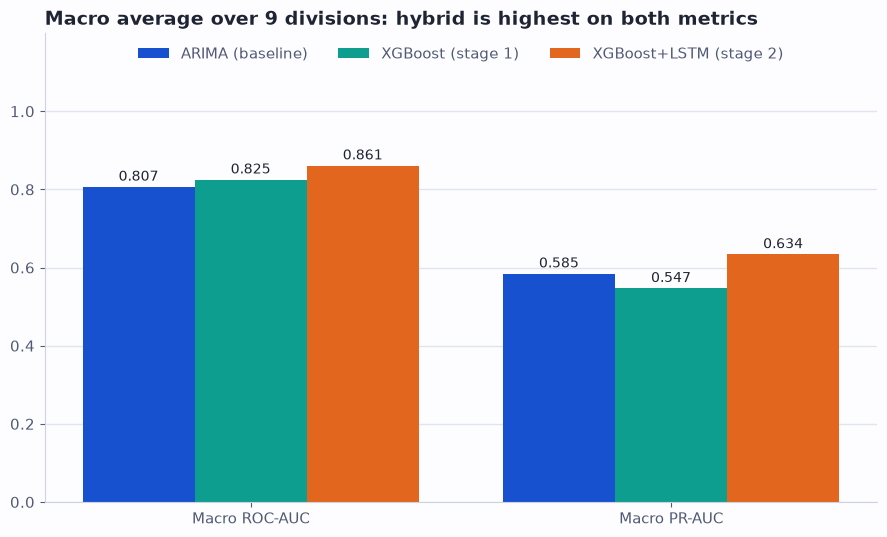

saved fig8_phase4_macro_summary.png


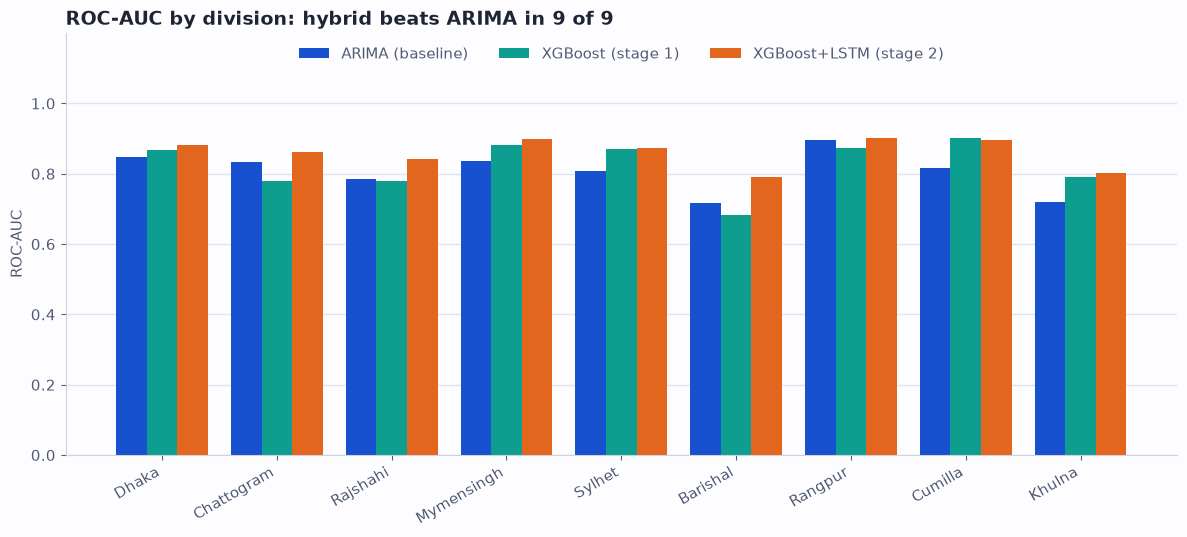

saved fig9_phase4_roc_auc.png


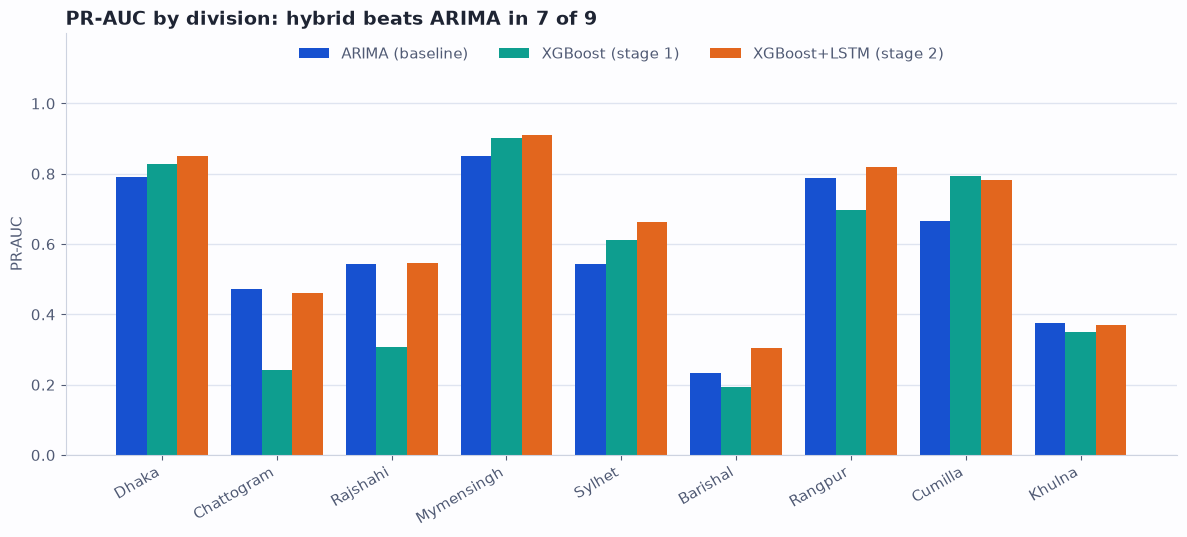

saved fig10_phase4_pr_auc.png


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TABLES, FIGURES = "../outputs/tables", "../outputs/figures"
os.makedirs(FIGURES, exist_ok=True)

# Palette
BLUE, ORANGE, AQUA = "#1751D0", "#E2661E", "#0E9E8F"
INK, INK2, GRID, SURF = "#1E2433", "#505A74", "#DFE4F0", "#FDFDFF"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#CDD3E0", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "figure.facecolor": SURF,
                     "axes.facecolor": SURF, "axes.spines.top": False, "axes.spines.right": False})

MODELS = [("arima", "ARIMA (baseline)", BLUE),
          ("xgb",   "XGBoost (stage 1)", AQUA),
          ("hyb",   "XGBoost+LSTM (stage 2)", ORANGE)]

# Division rows only; macro averages are computed from them
df = pd.read_csv(f"{TABLES}/phase4_results.csv")
df = df[df["division"] != "Macro avg"].reset_index(drop=True)
macro = df.drop(columns="division").mean()

def wins(metric):
    """Number of divisions where the hybrid beats ARIMA on `metric`."""
    return int((df[f"hyb_{metric}"] > df[f"arima_{metric}"]).sum())

def grouped_bars(ax, labels, series, title, ylabel=None, rotate=0, annotate=False):
    """series = [(legend label, colour, values), ...] drawn as grouped bars."""
    n, x = len(series), np.arange(len(labels))
    w = 0.8 / n
    for j, (name, color, vals) in enumerate(series):
        bars = ax.bar(x + (j - (n - 1) / 2) * w, vals, w, color=color, label=name)
        if annotate:
            ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=10, color=INK)
    ax.set_title(title, loc="left", color=INK, fontsize=14, fontweight="bold")
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=rotate, ha="right" if rotate else "center")
    ax.set_ylim(0, 1.2)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, labelcolor=INK2, ncol=3, loc="upper center")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/{name}", dpi=300, facecolor=SURF)
    plt.show()
    plt.close(fig)
    print("saved", name)

def division_series(metric):
    return [(label, color, df[f"{key}_{metric}"]) for key, label, color in MODELS]

# Fig 8: macro-average scoreboard
fig, ax = plt.subplots(figsize=(9, 5.5))
macro_series = [(label, color, [macro[f"{key}_roc"], macro[f"{key}_pr"]]) for key, label, color in MODELS]
grouped_bars(ax, ["Macro ROC-AUC", "Macro PR-AUC"], macro_series,
             f"Macro average over {len(df)} divisions: hybrid is highest on both metrics", annotate=True)
save(fig, "fig8_phase4_macro_summary.png")

# Fig 9: ROC-AUC by division
fig, ax = plt.subplots(figsize=(12, 5.5))
grouped_bars(ax, df["division"], division_series("roc"),
             f"ROC-AUC by division: hybrid beats ARIMA in {wins('roc')} of {len(df)}",
             ylabel="ROC-AUC", rotate=30)
save(fig, "fig9_phase4_roc_auc.png")

# Fig 10: PR-AUC by division
fig, ax = plt.subplots(figsize=(12, 5.5))
grouped_bars(ax, df["division"], division_series("pr"),
             f"PR-AUC by division: hybrid beats ARIMA in {wins('pr')} of {len(df)}",
             ylabel="PR-AUC", rotate=30)
save(fig, "fig10_phase4_pr_auc.png")